# Lab 6 – Frequency Domain Filtering

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.transform import resize
from numpy.fft import fft2, ifft2, fftshift, ifftshift

os.makedirs('images', exist_ok=True)

def show_side_by_side(images, titles, cmap=None):
    fig, ax = plt.subplots(1, len(images), figsize=(5 * len(images), 5))
    for a, im, t in zip(ax, images, titles):
        a.imshow(im, cmap=cmap); a.set_title(t); a.axis('off')
    plt.tight_layout(); plt.show()

## Task#1: Filtering in the Frequency Domain

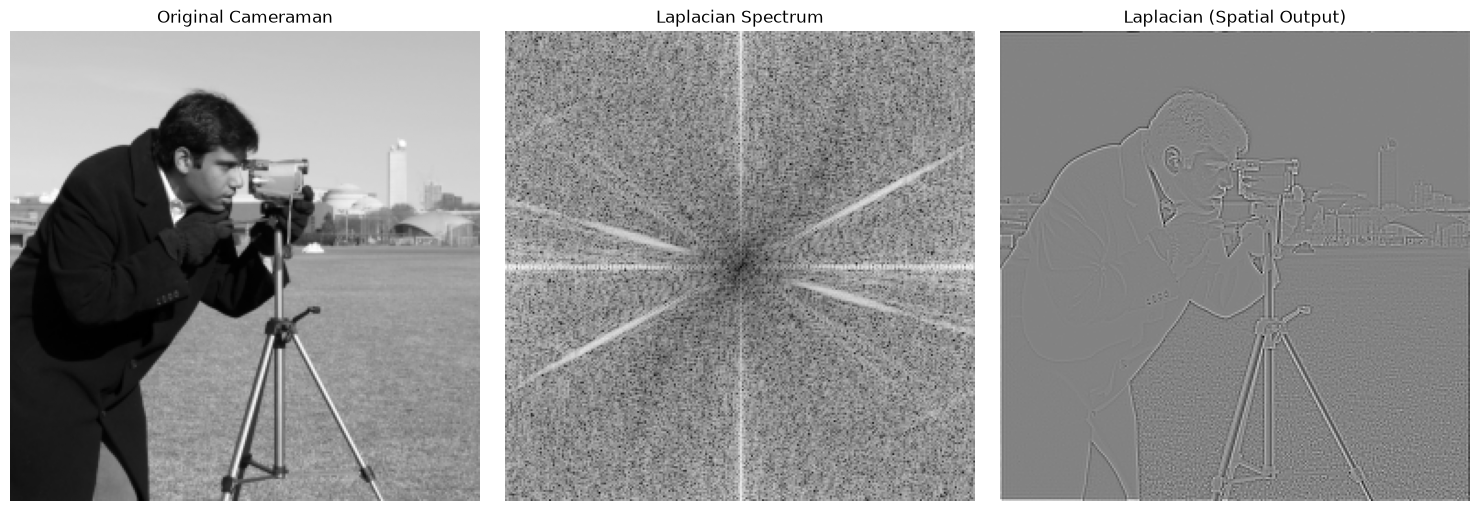

In [2]:
# Load cameraman image (already grayscale)
image = data.camera()
cv2.imwrite('images/cameraman.png', image)
image = resize(image, (256, 256))  # Resize for faster FFT

# Get image size
M, N = image.shape

# Generate frequency grid
u = np.fft.fftfreq(M).reshape(-1, 1)
v = np.fft.fftfreq(N).reshape(1, -1)

# Laplacian filter in frequency domain
laplacian_filter = -4 * (np.pi ** 2) * (u**2 + v**2)

# Apply 2D FFT
F = fft2(image)

# Apply Laplacian filter in frequency domain
F_lap = F * laplacian_filter

# Inverse FFT to get spatial result
laplacian_image = ifft2(F_lap).real

spectrum = np.log(1 + np.abs(fftshift(F_lap)))
show_side_by_side([image, spectrum, laplacian_image],
                  ['Original Cameraman', 'Laplacian Spectrum',
                   'Laplacian (Spatial Output)'], cmap='gray')

# Assessment

### Task#1: Sobel filters in the frequency domain

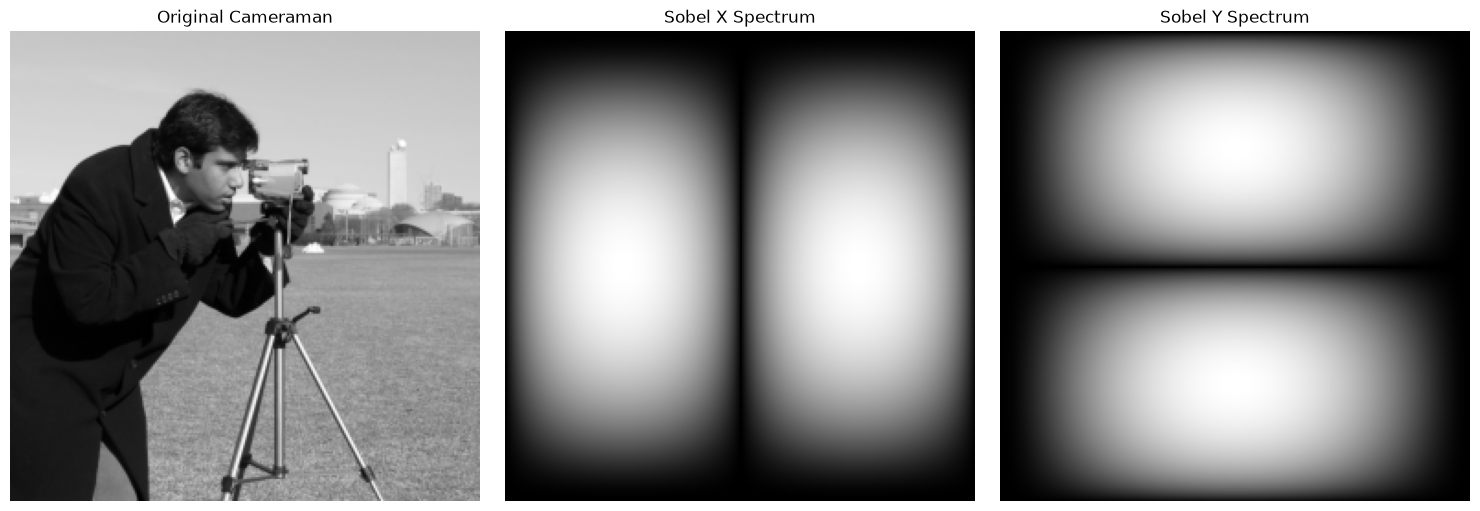

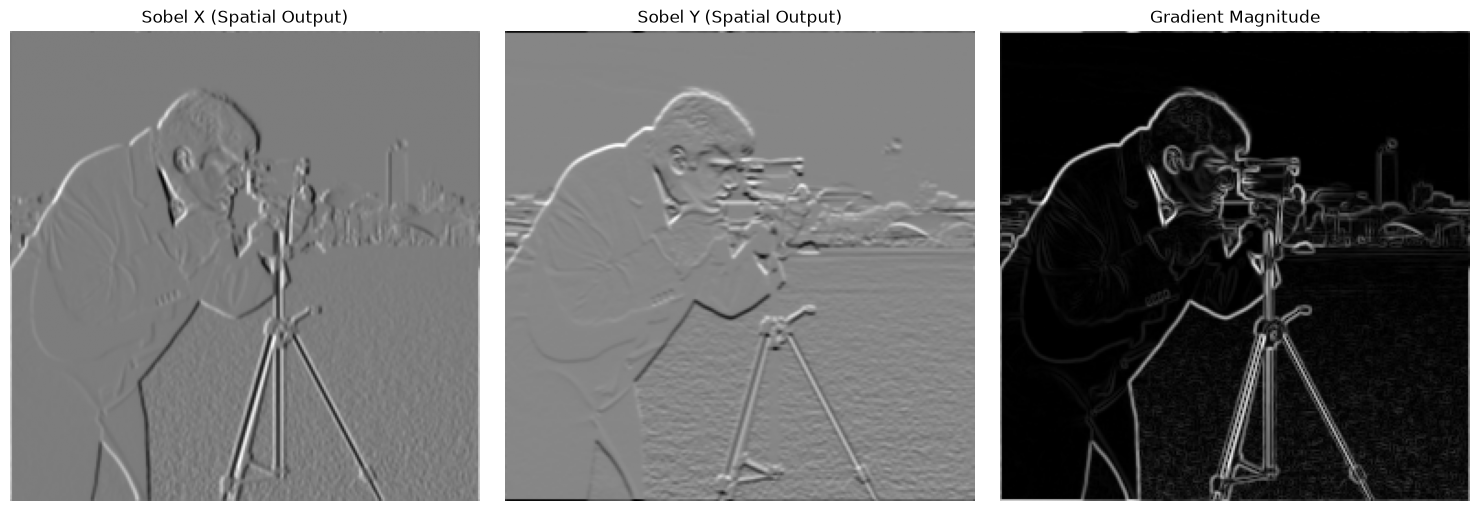

In [3]:
# Load and resize image
image = resize(data.camera(), (256, 256))

# Sobel filters
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])
sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]])

# Proper padding and centering of kernel in spatial domain
def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape
    cy, cx = ph // 2, pw // 2
    padded[cy - kh//2:cy - kh//2 + kh, cx - kw//2:cx - kw//2 + kw] = kernel
    # Shift before FFT to place (0,0) at top-left
    return fft2(ifftshift(padded))

# Compute FFT of image
F = fft2(image)

# FFT of centered Sobel filters
Hx = center_embed_kernel(sobel_x, image.shape)
Hy = center_embed_kernel(sobel_y, image.shape)

# Multiply in the frequency domain and go back to spatial domain
gx = ifft2(F * Hx).real
gy = ifft2(F * Hy).real
magnitude = np.sqrt(gx**2 + gy**2)

spec_x = np.log(1 + np.abs(fftshift(Hx)))
spec_y = np.log(1 + np.abs(fftshift(Hy)))

show_side_by_side([image, spec_x, spec_y],
                  ['Original Cameraman', 'Sobel X Spectrum',
                   'Sobel Y Spectrum'], cmap='gray')
show_side_by_side([gx, gy, magnitude],
                  ['Sobel X (Spatial Output)', 'Sobel Y (Spatial Output)',
                   'Gradient Magnitude'], cmap='gray')